Data for modelling (after cleaning and feature selection):
X shape: (814, 21)
y shape: (814,)

Train–Test Split:
Training samples: 651
Test samples:     163

3. BASELINE LINEAR REGRESSION (log_streams)
Train RMSE: 0.7098 | Test RMSE: 0.6792
Train R²  : 0.5500  | Test R²  : 0.5029

4. REGULARISED LINEAR REGRESSION

Ridge – Best hyper-parameters: {'model__alpha': 10.0}
Ridge – Train RMSE: 0.7101, Test RMSE: 0.6766
Ridge – Train R²:   0.5496, Test R²:   0.5068

Lasso – Best hyper-parameters: {'model__alpha': 0.01}
Lasso – Train RMSE: 0.7126, Test RMSE: 0.6734
Lasso – Train R²:   0.5465, Test R²:   0.5114

ElasticNet – Best hyper-parameters: {'model__alpha': 0.1, 'model__l1_ratio': 0.2}
ElasticNet – Train RMSE: 0.7227, Test RMSE: 0.6696
ElasticNet – Train R²:   0.5335, Test R²:   0.5168

5. GRADIENT BOOSTING REGRESSOR (GBR) – EVOLUTION

GBR (Untuned)
  Train RMSE: 0.2620, Test RMSE: 0.3442
  Train R²:   0.9387, Test R²:   0.8723

GBR Coarse Tuning – Best Params: {'learning_rate': 0.05, 'ma

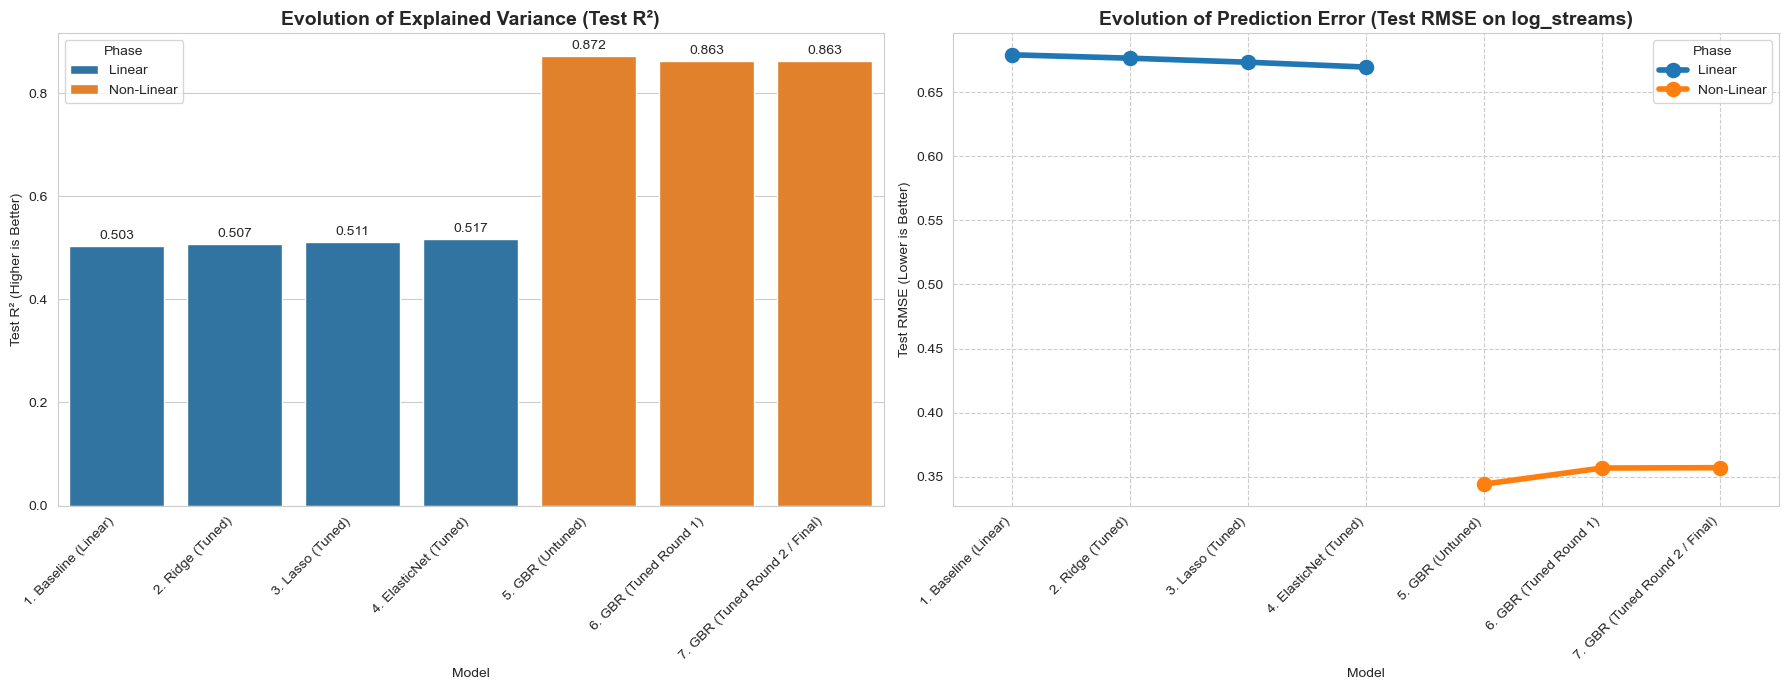

In [5]:
# =============================================================================
# FULL 7-MODEL COMPARISON ON log_streams
# Baseline Linear, Ridge, Lasso, ElasticNet, GBR (3 stages)
# Dataset: spotify_initial_prepared.csv
# =============================================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

sns.set_style("whitegrid")

# =============================================================================
# 1. DATA PREPARATION – log_streams TARGET (YOUR EXISTING LOGIC)
# =============================================================================

df = pd.read_csv("spotify_initial_prepared.csv", encoding="latin1")

numeric_cols_for_modelling = [
    "streams",
    "artist_count",
    "released_year",
    "released_month",
    "released_day",
    "in_spotify_playlists",
    "in_spotify_charts",
    "in_apple_playlists",
    "in_apple_charts",
    "in_deezer_playlists",
    "in_deezer_charts",
    "in_shazam_charts",
    "bpm",
    "danceability_%",
    "valence_%",
    "energy_%",
    "acousticness_%",
    "instrumentalness_%",
    "liveness_%",
    "speechiness_%",
]

# Clean numeric-like columns (remove commas, convert to numeric)
for col in numeric_cols_for_modelling:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.replace(",", "", regex=False)
        )
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Ensure log_streams exists
if "log_streams" not in df.columns:
    df["log_streams"] = np.log1p(df["streams"])
    print("log_streams was missing – recreated from streams.")

# Drop rows with missing values in important numeric cols or target
df = df.dropna(subset=numeric_cols_for_modelling + ["log_streams"])

target_col = "log_streams"

feature_cols = [
    "artist_count",
    "released_year",
    "released_month",
    "released_day",
    "in_spotify_playlists",
    "in_spotify_charts",
    "in_apple_playlists",
    "in_apple_charts",
    "in_deezer_playlists",
    "in_deezer_charts",
    "in_shazam_charts",
    "bpm",
    "danceability_%",
    "valence_%",
    "energy_%",
    "acousticness_%",
    "instrumentalness_%",
    "liveness_%",
    "speechiness_%",
    "key",
    "mode",
]

df_model = df[feature_cols + [target_col]].dropna()
X = df_model[feature_cols]
y = df_model[target_col]

print("Data for modelling (after cleaning and feature selection):")
print("X shape:", X.shape)
print("y shape:", y.shape)

# Train–test split (same for all 7 models)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTrain–Test Split:")
print("Training samples:", X_train.shape[0])
print("Test samples:    ", X_test.shape[0])

# =============================================================================
# 2. PREPROCESSOR & PIPELINE (YOUR REGULARISED- MODEL SETUP)
# =============================================================================

numeric_features = [
    "artist_count",
    "released_year",
    "released_month",
    "released_day",
    "in_spotify_playlists",
    "in_spotify_charts",
    "in_apple_playlists",
    "in_apple_charts",
    "in_deezer_playlists",
    "in_deezer_charts",
    "in_shazam_charts",
    "bpm",
    "danceability_%",
    "valence_%",
    "energy_%",
    "acousticness_%",
    "instrumentalness_%",
    "liveness_%",
    "speechiness_%",
]

categorical_features = ["key", "mode"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numeric_features),
    ]
)

def make_pipeline_with_model(model):
    return Pipeline(
        steps=[
            ("preprocess", preprocessor),
            ("scaler", StandardScaler(with_mean=False)),  # sparse-safe
            ("model", model),
        ]
    )

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# =============================================================================
# 3. BASELINE LINEAR REGRESSION (on log_streams)
# =============================================================================

print("\n" + "="*80)
print("3. BASELINE LINEAR REGRESSION (log_streams)")
print("="*80)

baseline_pipe = make_pipeline_with_model(LinearRegression())
baseline_pipe.fit(X_train, y_train)

y_train_pred_lin = baseline_pipe.predict(X_train)
y_test_pred_lin = baseline_pipe.predict(X_test)

lin_train_rmse = rmse(y_train, y_train_pred_lin)
lin_test_rmse  = rmse(y_test,  y_test_pred_lin)
lin_train_r2   = r2_score(y_train, y_train_pred_lin)
lin_test_r2    = r2_score(y_test,  y_test_pred_lin)

print(f"Train RMSE: {lin_train_rmse:.4f} | Test RMSE: {lin_test_rmse:.4f}")
print(f"Train R²  : {lin_train_r2:.4f}  | Test R²  : {lin_test_r2:.4f}")

lin_metrics = {
    "Train_RMSE": lin_train_rmse,
    "Test_RMSE": lin_test_rmse,
    "Train_R2": lin_train_r2,
    "Test_R2": lin_test_r2,
}

# =============================================================================
# 4. REGULARISED LINEAR MODELS (RIDGE, LASSO, ELASTICNET) – YOUR TUNING
# =============================================================================

print("\n" + "="*80)
print("4. REGULARISED LINEAR REGRESSION")
print("="*80)

ridge_param_grid = {
    "model__alpha": [0.1, 1.0, 10.0, 100.0]
}

lasso_param_grid = {
    "model__alpha": [0.0005, 0.001, 0.01, 0.1, 1.0]
}

elasticnet_param_grid = {
    "model__alpha": [0.0005, 0.001, 0.01, 0.1, 1.0],
    "model__l1_ratio": [0.2, 0.5, 0.8],
}

def tune_model(name, base_estimator, param_grid):
    pipe = make_pipeline_with_model(base_estimator)

    grid_search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
        verbose=0,
    )

    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_

    y_train_pred = best_model.predict(X_train)
    y_test_pred  = best_model.predict(X_test)

    rmse_train = rmse(y_train, y_train_pred)
    rmse_test  = rmse(y_test,  y_test_pred)
    r2_train   = r2_score(y_train, y_train_pred)
    r2_test    = r2_score(y_test,  y_test_pred)

    metrics = {
        "Train_RMSE": rmse_train,
        "Test_RMSE": rmse_test,
        "Train_R2": r2_train,
        "Test_R2": r2_test,
    }

    print(f"\n{name} – Best hyper-parameters: {grid_search.best_params_}")
    print(f"{name} – Train RMSE: {rmse_train:.4f}, Test RMSE: {rmse_test:.4f}")
    print(f"{name} – Train R²:   {r2_train:.4f}, Test R²:   {r2_test:.4f}")

    return best_model, metrics

ridge_best, ridge_metrics = tune_model("Ridge", Ridge(random_state=42), ridge_param_grid)
lasso_best, lasso_metrics = tune_model("Lasso", Lasso(random_state=42, max_iter=10000), lasso_param_grid)
elasticnet_best, elasticnet_metrics = tune_model("ElasticNet", ElasticNet(random_state=42, max_iter=10000), elasticnet_param_grid)

# =============================================================================
# 5. GRADIENT BOOSTING REGRESSOR (3 STAGES) – USING YOUR LOGIC
# =============================================================================

print("\n" + "="*80)
print("5. GRADIENT BOOSTING REGRESSOR (GBR) – EVOLUTION")
print("="*80)

# For GBR, we use numeric-only features + label-encoded key/mode
df_model_gbr = df_model.copy()

le_key = LabelEncoder()
le_mode = LabelEncoder()
df_model_gbr["key_le"]  = le_key.fit_transform(df_model_gbr["key"].astype(str))
df_model_gbr["mode_le"] = le_mode.fit_transform(df_model_gbr["mode"].astype(str))

gbr_features = numeric_features + ["key_le", "mode_le"]
X_gbr = df_model_gbr[gbr_features]
y_gbr = df_model_gbr[target_col]

# Align train/test split with linear models (same indices)
X_train_gbr = X_gbr.loc[X_train.index]
X_test_gbr  = X_gbr.loc[X_test.index]
y_train_gbr = y_train
y_test_gbr  = y_test

def evaluate_gbr(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_tr_pred = model.predict(X_tr)
    y_te_pred = model.predict(X_te)

    rmse_tr = rmse(y_tr, y_tr_pred)
    rmse_te = rmse(y_te, y_te_pred)
    mae_te  = mean_absolute_error(y_te, y_te_pred)
    r2_tr   = r2_score(y_tr, y_tr_pred)
    r2_te   = r2_score(y_te, y_te_pred)

    print(f"\n{name}")
    print(f"  Train RMSE: {rmse_tr:.4f}, Test RMSE: {rmse_te:.4f}")
    print(f"  Train R²:   {r2_tr:.4f}, Test R²:   {r2_te:.4f}")

    return {
        "Train_RMSE": rmse_tr,
        "Test_RMSE": rmse_te,
        "Train_R2": r2_tr,
        "Test_R2": r2_te,
        "Test_MAE": mae_te,
    }

# A. Untuned GBR
gbr_untuned = GradientBoostingRegressor(random_state=42)
gbr_untuned_metrics = evaluate_gbr(
    "GBR (Untuned)",
    gbr_untuned,
    X_train_gbr,
    y_train_gbr,
    X_test_gbr,
    y_test_gbr,
)

# B. Coarse tuning (Round 1)
param_grid_coarse = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.05, 0.1, 0.2],
    "max_depth": [3, 4, 5],
}

grid_coarse = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid_coarse,
    scoring="r2",
    cv=3,
    n_jobs=-1,
    verbose=0,
)

grid_coarse.fit(X_train_gbr, y_train_gbr)
best_coarse = grid_coarse.best_estimator_

print("\nGBR Coarse Tuning – Best Params:", grid_coarse.best_params_)

gbr_coarse_metrics = evaluate_gbr(
    "GBR (Tuned Round 1)",
    best_coarse,
    X_train_gbr,
    y_train_gbr,
    X_test_gbr,
    y_test_gbr,
)

# C. Fine tuning (Round 2 / Final)
bp = grid_coarse.best_params_

param_grid_fine = {
    "n_estimators": [bp["n_estimators"], bp["n_estimators"] + 50],
    "learning_rate": [bp["learning_rate"] * 0.9, bp["learning_rate"], bp["learning_rate"] * 1.1],
    "max_depth": [bp["max_depth"]],
    "min_samples_split": [2, 5],
}

grid_fine = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid_fine,
    scoring="r2",
    cv=3,
    n_jobs=-1,
    verbose=0,
)

grid_fine.fit(X_train_gbr, y_train_gbr)
best_fine = grid_fine.best_estimator_

print("\nGBR Fine Tuning – Best Params:", grid_fine.best_params_)

gbr_fine_metrics = evaluate_gbr(
    "GBR (Tuned Round 2 / Final)",
    best_fine,
    X_train_gbr,
    y_train_gbr,
    X_test_gbr,
    y_test_gbr,
)

# =============================================================================
# 6. MASTER EVOLUTION SUMMARY – 7 MODELS
# =============================================================================

evolution_data = [
    {
        "Model": "1. Baseline (Linear)",
        "Phase": "Linear",
        "Test RMSE": lin_metrics["Test_RMSE"],
        "Test R2": lin_metrics["Test_R2"],
    },
    {
        "Model": "2. Ridge (Tuned)",
        "Phase": "Linear",
        "Test RMSE": ridge_metrics["Test_RMSE"],
        "Test R2": ridge_metrics["Test_R2"],
    },
    {
        "Model": "3. Lasso (Tuned)",
        "Phase": "Linear",
        "Test RMSE": lasso_metrics["Test_RMSE"],
        "Test R2": lasso_metrics["Test_R2"],
    },
    {
        "Model": "4. ElasticNet (Tuned)",
        "Phase": "Linear",
        "Test RMSE": elasticnet_metrics["Test_RMSE"],
        "Test R2": elasticnet_metrics["Test_R2"],
    },
    {
        "Model": "5. GBR (Untuned)",
        "Phase": "Non-Linear",
        "Test RMSE": gbr_untuned_metrics["Test_RMSE"],
        "Test R2": gbr_untuned_metrics["Test_R2"],
    },
    {
        "Model": "6. GBR (Tuned Round 1)",
        "Phase": "Non-Linear",
        "Test RMSE": gbr_coarse_metrics["Test_RMSE"],
        "Test R2": gbr_coarse_metrics["Test_R2"],
    },
    {
        "Model": "7. GBR (Tuned Round 2 / Final)",
        "Phase": "Non-Linear",
        "Test RMSE": gbr_fine_metrics["Test_RMSE"],
        "Test R2": gbr_fine_metrics["Test_R2"],
    },
]

evo_df = pd.DataFrame(evolution_data)

print("\n" + "="*80)
print("MASTER EVOLUTION SUMMARY – 7 MODELS (log_streams, same split)")
print("="*80)
print(evo_df.to_markdown(index=False, floatfmt=".4f"))

# =============================================================================
# 7. VISUALISATION – R² AND RMSE EVOLUTION
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1: R² evolution
sns.barplot(
    data=evo_df,
    x="Model",
    y="Test R2",
    hue="Phase",
    dodge=False,
    ax=axes[0],
)
axes[0].set_title("Evolution of Explained Variance (Test R²)", fontsize=14, fontweight="bold")
axes[0].set_xticklabels(evo_df["Model"], rotation=45, ha="right")
axes[0].set_ylabel("Test R² (Higher is Better)")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", padding=3)

# Plot 2: RMSE evolution
sns.pointplot(
    data=evo_df,
    x="Model",
    y="Test RMSE",
    hue="Phase",
    ax=axes[1],
    scale=1.5,
)
axes[1].set_title("Evolution of Prediction Error (Test RMSE on log_streams)", fontsize=14, fontweight="bold")
axes[1].set_xticklabels(evo_df["Model"], rotation=45, ha="right")
axes[1].set_ylabel("Test RMSE (Lower is Better)")
axes[1].grid(True, linestyle="--")

handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(handles[:2], labels[:2], title="Phase")

plt.tight_layout()
plt.show()
